In [ ]:
import numpy as np
import pandas as pd

marks = {'Maths': 85, 'Science': 92, 'English': 78}

# Create Series from dictionary
result = pd.Series(marks)

# Access English marks
print(result['English'])

# Data type of the Series
print(result.dtype)

# Number of elements in the Series
print(result.size)

# Index labels of the Series
print(result.keys())

# Values of the Series as NumPy array
print(result.values)

# Index of the Series
print(result.index)


78
int64
3


In [16]:
import pandas as pd
import numpy as np

marks = [10, None, 30, None, 50]

# Create Series
result = pd.Series(marks)

# Check which values are NOT NaN
print(~result.isna())

# Add 5 to all elements
result = result + 5

# Calculate mean of the Series
print(result.mean())

# Filter values greater than 2
print(result[result > 2])

# Print final Series
print(result)


0     True
1    False
2     True
3    False
4     True
dtype: bool
35.0
0    15.0
2    35.0
4    55.0
dtype: float64
0    15.0
1     NaN
2    35.0
3     NaN
4    55.0
dtype: float64


###`Q-1:` Write a program to create an empty series.

In [1]:
# code here
# creating empty series 
import numpy as np 
import pandas as pd


# method -1 
empty_series=pd.Series()
print(empty_series)


Series([], dtype: object)


###`Q-2:` Write a Pandas program to add, subtract, multiple and divide two Pandas Series.

In [ ]:
# code here
# adding , subtracting , multiplying and dividing two panda series 

import pandas as pd 

# method -1   
a=pd.Series([1,2,3,4,5])
b=pd.Series([1,3,5,7,9])
print(a*b)
print(a-b)
print(a*b)




###`Q-3` Write a Pandas program to compare the elements of the two Pandas Series.
Sample Series: [2, 4, 6, 8, 10], [1, 3, 5, 7, 10]



In [ ]:
# code here
# comparing two panda series 
import pandas as pd 

# method 
series1=pd.Series([1,2,3,4,5])
series2=pd.Series([6,7,8,9,10])
series3=series1>series2

print(series3)
print(series1==series2)
print(series1<series2)


###`Q-5.`Write a function to change the data type of given a column or a Series. Function takes series and data type as input, returns the converted series.
```
series = pd.Series([1,2,'Python', 2.0, True, 100])
change to float type data
```
Note: Read about pd.to_numeric()

In [ ]:
# --------------------------------------------------
# Convert only integer values in a Pandas Series
# to float
# --------------------------------------------------

import pandas as pd
import numpy as np


# ==================================================
# Method 1: Using loop + type checking
# ==================================================

# Time Complexity: O(n)              # single traversal
# Space Complexity: O(1)             # in-place update

series = pd.Series([1, 2, 'Python', 2.0, True, 100])

for i in range(len(series)):
    if isinstance(series[i], int) and not isinstance(series[i], bool):
        series[i] = float(series[i])            # convert int → float

print("After Method 1:")
print(series)






# ==================================================
# Method 2: Using pd.to_numeric()
# ==================================================

# Time Complexity: O(n)
# Space Complexity: O(n)             # new Series created

series2 = pd.Series([1, 2, 'Python', 2.0, True, 100])

series2 = pd.to_numeric(series2, errors='ignore')   # converts numeric strings
series2 = series2.apply(
    lambda x: float(x) if isinstance(x, int) and not isinstance(x, bool) else x
)

print("\nAfter Method 2:")
print(series2)


Download data - https://drive.google.com/file/d/1LRhXwbEodeWXtzPhJCX0X9Lf_BECzvqb/view?usp=share_link
All Batsman runs series in IPL 2008 to 2022.

Below questions are based on this data.

###`Q-6` Find top 10 most run getter from the series.

In [28]:
# code here
#  getting scores of top 10 batters 
import pandas as pd 

# simple method -1 
batsman_df=pd.read_csv('content/batsman_runs_series.csv')
batsman_df.sort_values('batsman_run' ,ascending=False).head(10)

# method - 2
# group by batsman and sum their runs
top_10_batters = (
    batsman_df
    .groupby('batter')['batsman_run']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_10_batters)


batter
V Kohli           6634
S Dhawan          6244
DA Warner         5883
RG Sharma         5881
SK Raina          5536
AB de Villiers    5181
CH Gayle          4997
MS Dhoni          4978
RV Uthappa        4954
KD Karthik        4377
Name: batsman_run, dtype: int64


###`Q-7` No of players having runs above 3000

In [31]:
# code here
# no of players having runs above 3000 
# method -1  using loops

# method -2
batsman_df[batsman_df['batsman_run']>3000].shape[0]



20

###`Q-8` No of players having runs above mean value?

In [33]:
batsman_df[batsman_df['batsman_run']>batsman_df['batsman_run'].mean()]

,batter,batsman_run
15,A Symonds,974
27,AB de Villiers,5181
29,AC Gilchrist,2069
34,AD Mathews,724
36,AD Russell,2039
...,...,...
587,WP Saha,2427
594,Y Venugopal Rao,985
596,YBK Jaiswal,547
597,YK Pathan,3222


Download data - https://drive.google.com/file/d/1QZuZ5bypUInfVvarHACLAi8tXXHvb8xd/view?usp=share_link

file name - items.csv



###`Q-9`
    i. Read `items.csv` making `item_name` as index.
    ii. Show no of nan values
    ii. Item price is given in $, so convert it to rupees without currency symbol.
    iii. Make data type of newly made series as float.
    iv. Fill nan with mean of the series


How csv file looks

```
item_name	item_price
Chips and Fresh Tomato Salsa	$2.39
Izze	$3.39
Nantucket Nectar	$3.39
Chips and Tomatillo-Green Chili Salsa	$2.39
Chicken Bowl	$16.98

```

In [40]:
# --------------------------------------------------
# Q-9 Solution
# --------------------------------------------------

import pandas as pd

# --------------------------------------------------
# i. Read items.csv & make item_name as index
# --------------------------------------------------

items = pd.read_csv('content/items.csv')
items.set_index('item_name', inplace=True)

# --------------------------------------------------
# ii. Show number of NaN values
# --------------------------------------------------

print("NaN values per column:")
print(items.isna().sum())

# --------------------------------------------------
# iii. Convert item_price from $ to rupees (₹)
# --------------------------------------------------

# remove $ sign
items['item_price'] = items['item_price'].str.replace('$', '', regex=False)

# convert to float
items['item_price'] = items['item_price'].astype(float)

# convert dollars to rupees (1$ = 83₹ approx)
items['item_price'] = items['item_price'] * 83

# --------------------------------------------------
# iv. Fill NaN with mean of the series
# --------------------------------------------------

mean_price = items['item_price'].mean()
items['item_price'].fillna(mean_price, inplace=True)

print("\nFinal cleaned data:")
print(items.head())


NaN values per column:
item_price    50
dtype: int64

Final cleaned data:
                                       item_price
item_name                                        
Chips and Fresh Tomato Salsa               198.37
Izze                                       281.37
Nantucket Nectar                           281.37
Chips and Tomatillo-Green Chili Salsa      198.37
Chicken Bowl                              1409.34


C:\Users\Aayu0\AppData\Local\Temp\ipykernel_4484\1779430368.py:39: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  items['item_price'].fillna(mean_price, inplace=True)


###`Q-10`:
    i. Find mean price
    ii. Find 30th and 6th percentile value
    iii. Plot Histogram on price with bin size 50
    iv. No of items price lies between [1000 to 2000]



Mean Price: 619.4316141732284
30th Percentile: 369.35
6th Percentile: 103.75


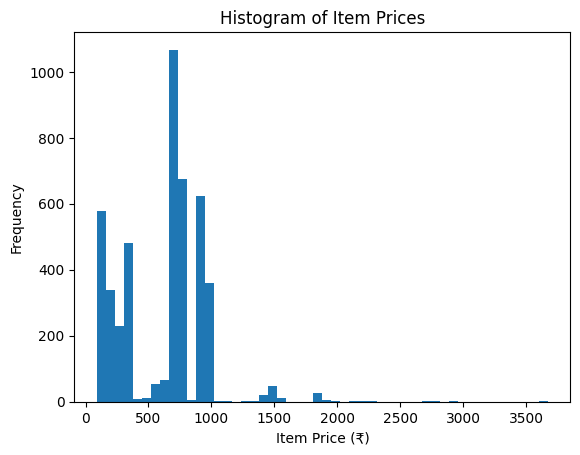

Items priced between ₹1000 and ₹2000: 116


In [42]:
import pandas as pd
import matplotlib.pyplot as plt

# Time Complexity: O(n)
# Space Complexity: O(1)

mean_price = items['item_price'].mean()
print("Mean Price:", mean_price)

# Time Complexity: O(n)
# Space Complexity: O(1)

p30 = items['item_price'].quantile(0.30)
p06 = items['item_price'].quantile(0.06)

print("30th Percentile:", p30)
print("6th Percentile:", p06)
# Time Complexity: O(n)
# Space Complexity: O(n)

plt.figure()
plt.hist(items['item_price'], bins=50)
plt.xlabel("Item Price (₹)")
plt.ylabel("Frequency")
plt.title("Histogram of Item Prices")
plt.show()


# Time Complexity: O(n)
# Space Complexity: O(1)

count_items = items[
    (items['item_price'] >= 1000) & 
    (items['item_price'] <= 2000)
].shape[0]

print("Items priced between ₹1000 and ₹2000:", count_items)

